   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1             59 rue de l'Abbaye           NaN

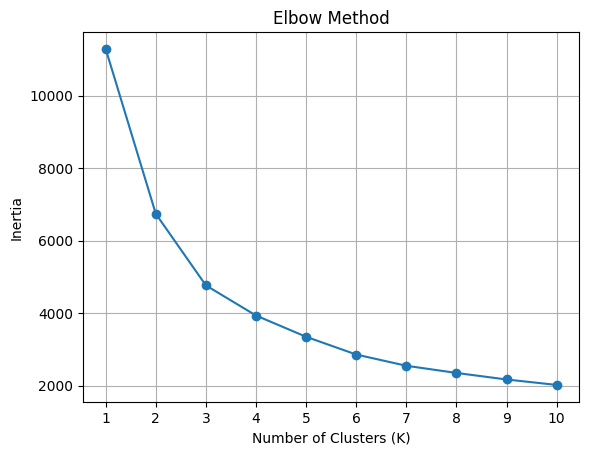

     SALES  QUANTITYORDERED  PRICEEACH  MSRP  Cluster
0  2871.00               30      95.70    95        2
1  2765.90               34      81.35    95        2
2  3884.34               41      94.74    95        1
3  3746.70               45      83.26    95        1
4  5205.27               49     100.00    95        1


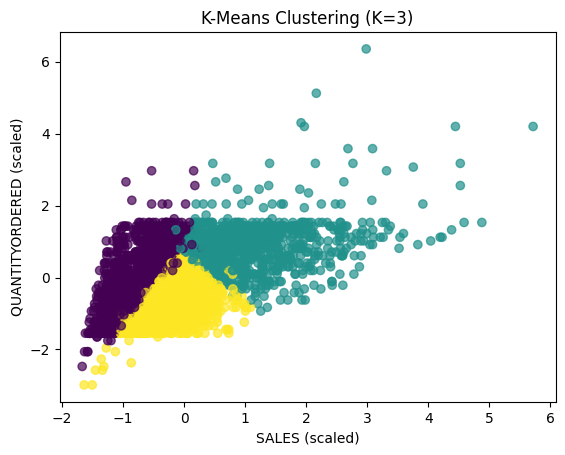

Cluster
0    975
1    852
2    996
Name: count, dtype: int64


In [1]:
# 1. Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 2. Load the dataset
df = pd.read_csv("sales_data_sample.csv", encoding="latin1")

# 3. Display basic information
print(df.head())
print(df.shape)
print(df.isnull().sum())

# 4. Select numerical sales-related features
candidate_features = [
    "SALES",
    "QUANTITYORDERED",
    "PRICEEACH",
    "MSRP"
]

features = [col for col in candidate_features if col in df.columns]

if len(features) < 2:
    raise ValueError(
        "Dataset must contain at least two of these columns: "
        "SALES, QUANTITYORDERED, PRICEEACH, MSRP"
    )

X = df[features].copy()

# 5. Handle missing values
X = X.fillna(X.median())

# 6. Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 7. Apply the Elbow Method
inertia = []
K_range = range(1, 11)

for k in K_range:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia.append(model.inertia_)

# 8. Plot the Elbow curve
plt.plot(K_range, inertia, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(K_range))
plt.grid(True)
plt.show()

# 9. Choose K after inspecting the Elbow plot
optimal_k = 3  # Example only; verify using your graph

# 10. Train the final K-Means model
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = kmeans.fit_predict(X_scaled)

# 11. Display the cluster assignments
print(df[features + ["Cluster"]].head())

# 12. Visualize clusters using the first two selected features
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    alpha=0.7
)

plt.xlabel(features[0] + " (scaled)")
plt.ylabel(features[1] + " (scaled)")
plt.title(f"K-Means Clustering (K={optimal_k})")
plt.show()

# 13. Display the number of records in each cluster
print(df["Cluster"].value_counts().sort_index())